In [483]:
import numpy as np
from scipy import interpolate
import matplotlib.pyplot as plt

In [484]:
N = 128

np.random.seed(42)
t_k = np.cumsum(np.random.rand(1, N))
t_k -= t_k[0]  # Make it start at 0

fs = N / t_k[-1]
t_eq = np.linspace(t_k[0], t_k[-1], N)

fs

t_k.shape

(128,)

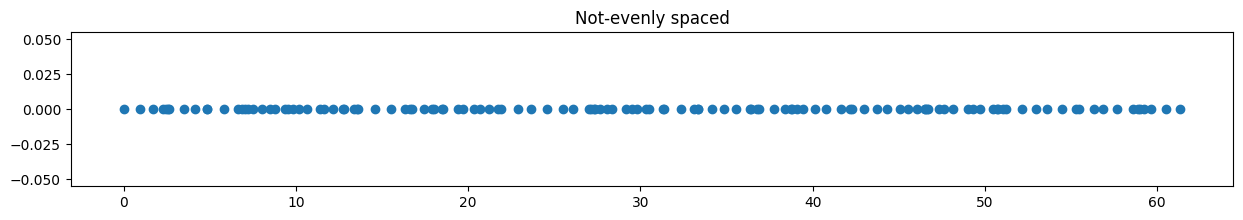

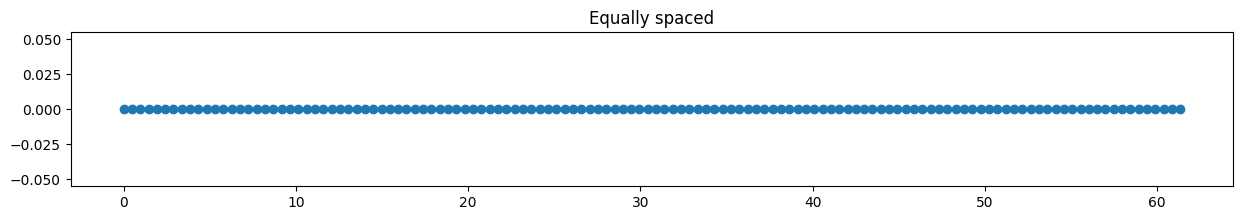

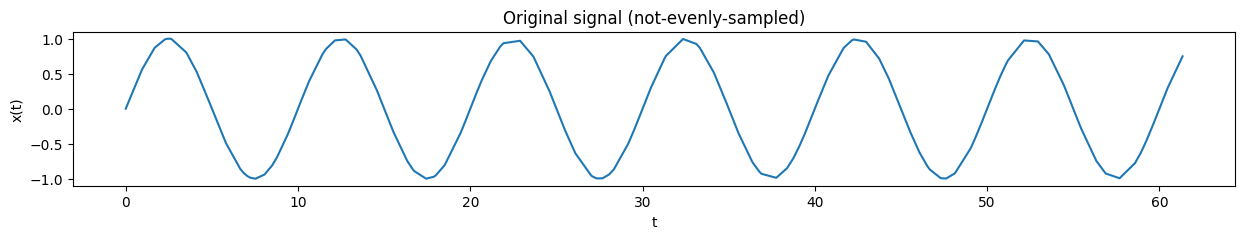

(128,)

In [485]:
f_signal = 0.1
x_nes = np.sin(2 * np.pi * f_signal * t_k)

plt.figure(figsize = (15,2))
plt.scatter(t_k, np.zeros_like(t_k))
plt.title("Not-evenly spaced")
plt.show()

plt.figure(figsize = (15,2))
plt.scatter(t_eq, np.zeros_like(t_k))
plt.title("Equally spaced")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Original signal (not-evenly-sampled)")
plt.show()

t_k.shape

In [486]:
f_vec = np.fft.rfftfreq(N, d=N/t_k[-1])
# f_vec = np.arange(0, fs/2, 0.005)
f_vec.shape, f_vec[1] - f_vec[0], (f_vec[0], f_vec[-1])

((65,), 0.003744143370241515, (0.0, 0.23962517569545697))

In [487]:
f_vec

array([0.        , 0.00374414, 0.00748829, 0.01123243, 0.01497657,
       0.01872072, 0.02246486, 0.026209  , 0.02995315, 0.03369729,
       0.03744143, 0.04118558, 0.04492972, 0.04867386, 0.05241801,
       0.05616215, 0.05990629, 0.06365044, 0.06739458, 0.07113872,
       0.07488287, 0.07862701, 0.08237115, 0.0861153 , 0.08985944,
       0.09360358, 0.09734773, 0.10109187, 0.10483601, 0.10858016,
       0.1123243 , 0.11606844, 0.11981259, 0.12355673, 0.12730087,
       0.13104502, 0.13478916, 0.1385333 , 0.14227745, 0.14602159,
       0.14976573, 0.15350988, 0.15725402, 0.16099816, 0.16474231,
       0.16848645, 0.1722306 , 0.17597474, 0.17971888, 0.18346303,
       0.18720717, 0.19095131, 0.19469546, 0.1984396 , 0.20218374,
       0.20592789, 0.20967203, 0.21341617, 0.21716032, 0.22090446,
       0.2246486 , 0.22839275, 0.23213689, 0.23588103, 0.23962518])

In [488]:
def P(x, f) -> float:
    return (np.sum(x * np.cos(2 * np.pi * f * t_k))**2 + np.sum(x * np.sin(2 * np.pi * f * t_k))**2) / N

def calc_peridogram(x) -> np.ndarray:
    per = np.array([P(x, f_one) for f_one in f_vec])
    # per *= 2 / len(f_vec)
    return per

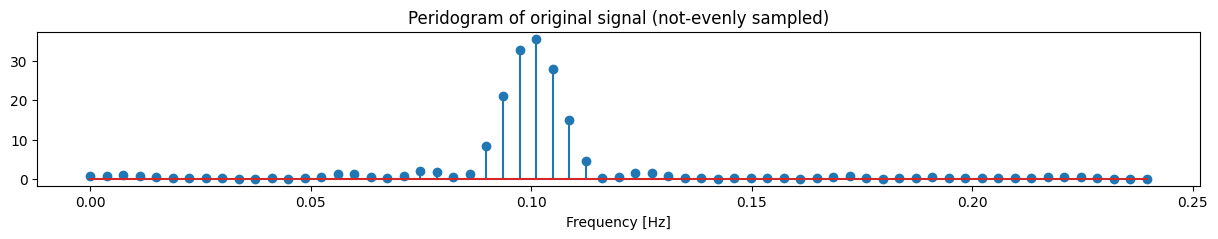

In [489]:
peridogram_original = calc_peridogram(x_nes)

plt.figure(figsize = (15,2))
plt.title("Peridogram of original signal (not-evenly sampled)")
plt.stem(f_vec, peridogram_original)
plt.xlabel("Frequency [Hz]")
plt.show()

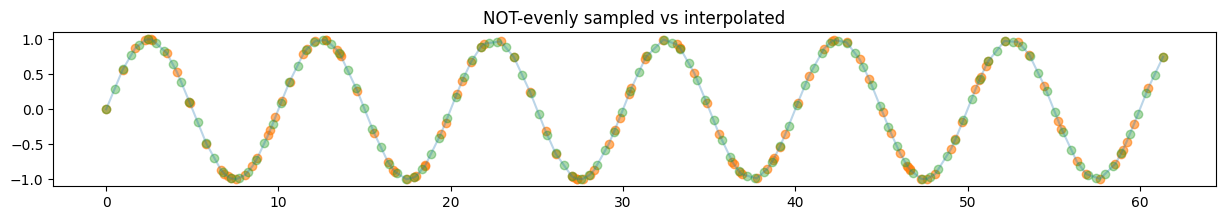

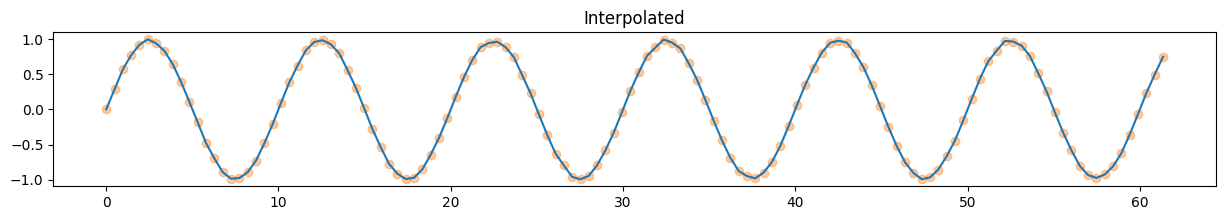

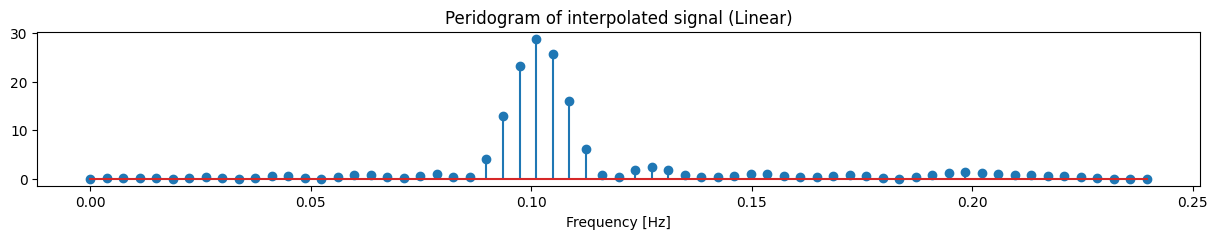

In [490]:
x_lin = np.interp(t_eq, t_k, x_nes)

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes, alpha=0.3)
plt.scatter(t_k, x_nes, color="tab:orange", alpha=0.6)
plt.scatter(t_eq, x_lin, color="tab:green", alpha=0.4)
plt.title("NOT-evenly sampled vs interpolated")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_eq, x_lin)
plt.title("Interpolated")
plt.scatter(t_eq, x_lin, color="tab:orange", alpha=0.4)
plt.show()

peridogram_lin = calc_peridogram(x_lin)

plt.figure(figsize = (15,2))
plt.title("Peridogram of interpolated signal (Linear)")
plt.stem(f_vec, peridogram_lin)
plt.xlabel("Frequency [Hz]")
plt.show()

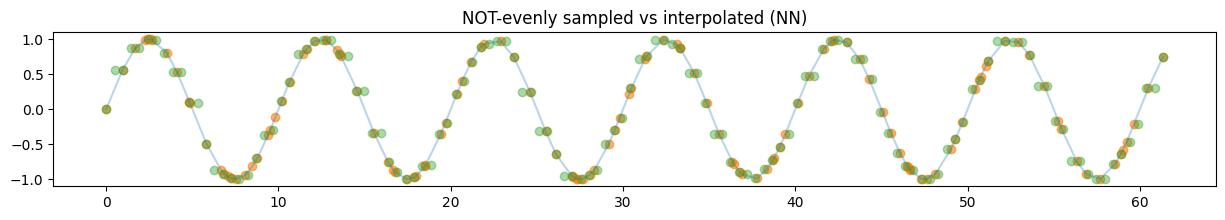

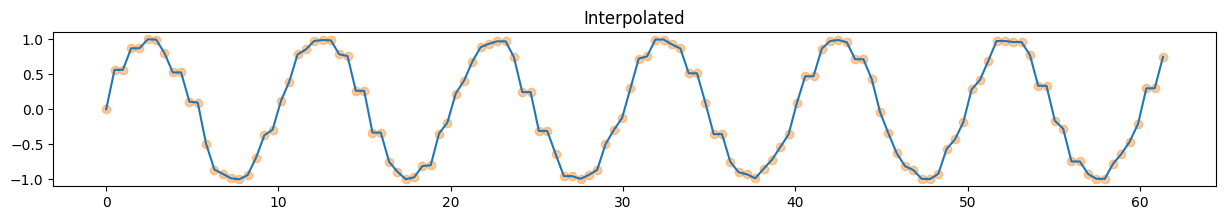

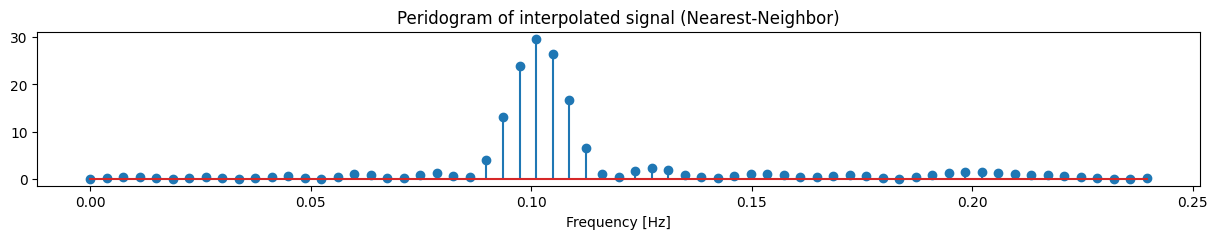

In [491]:
nnInterpolator = interpolate.interp1d(t_k, x_nes, kind="nearest")
x_nn = nnInterpolator(t_eq)

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes, alpha=0.3)
plt.scatter(t_k, x_nes, color="tab:orange", alpha=0.6)
plt.scatter(t_eq, x_nn, color="tab:green", alpha=0.4)
plt.title("NOT-evenly sampled vs interpolated (NN)")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_eq, x_nn)
plt.title("Interpolated")
plt.scatter(t_eq, x_nn, color="tab:orange", alpha=0.4)
plt.show()

peridogram_nn = calc_peridogram(x_nn)

plt.figure(figsize = (15,2))
plt.title("Peridogram of interpolated signal (Nearest-Neighbor)")
plt.stem(f_vec, peridogram_nn)
plt.xlabel("Frequency [Hz]")
plt.show()

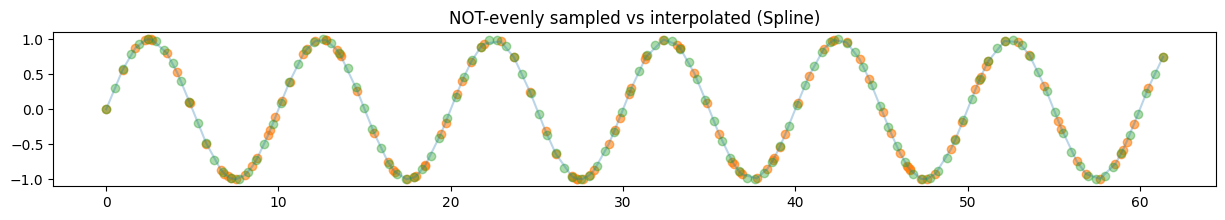

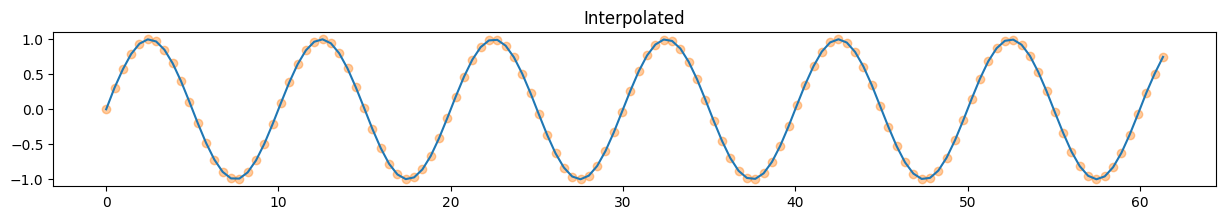

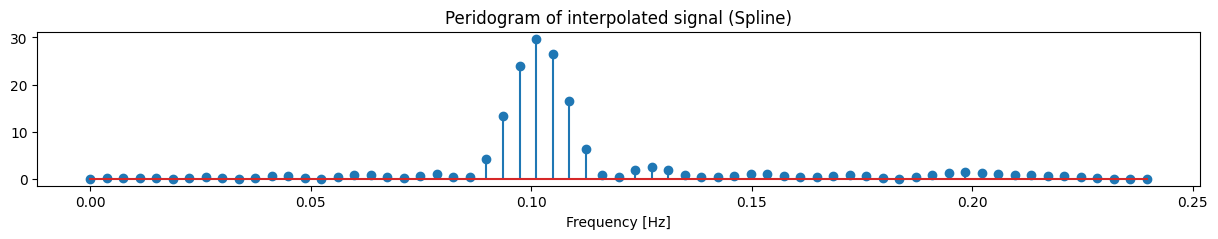

In [492]:
splineInterpolator = interpolate.interp1d(t_k, x_nes, kind="quadratic")
x_spline = splineInterpolator(t_eq)

plt.figure(figsize = (15,2))
plt.plot(t_k, x_nes, alpha=0.3)
plt.scatter(t_k, x_nes, color="tab:orange", alpha=0.6)
plt.scatter(t_eq, x_spline, color="tab:green", alpha=0.4)
plt.title("NOT-evenly sampled vs interpolated (Spline)")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t_eq, x_spline)
plt.title("Interpolated")
plt.scatter(t_eq, x_spline, color="tab:orange", alpha=0.4)
plt.show()

peridogram_spline = calc_peridogram(x_spline)

plt.figure(figsize = (15,2))
plt.title("Peridogram of interpolated signal (Spline)")
plt.stem(f_vec, peridogram_spline)
plt.xlabel("Frequency [Hz]")
plt.show()

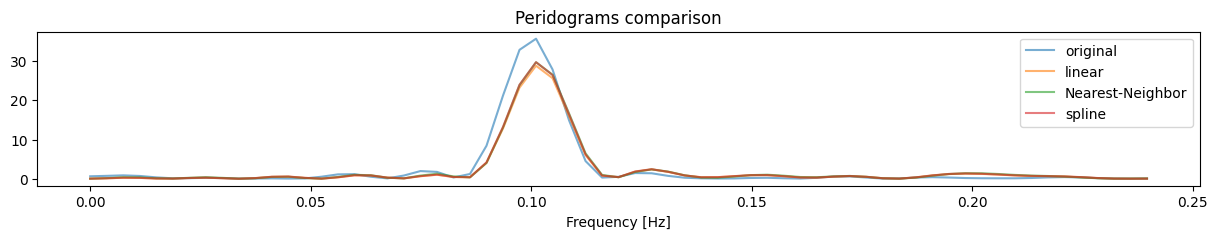

In [493]:
plt.figure(figsize = (15,2))
plt.title("Peridograms comparison")
plt.plot(f_vec, peridogram_original, label="original", alpha=0.6)
plt.plot(f_vec, peridogram_lin, label="linear", alpha=0.6)
plt.plot(f_vec, peridogram_nn, label="Nearest-Neighbor", alpha=0.6)
plt.plot(f_vec, peridogram_spline, label="spline", alpha=0.6)
plt.legend()
plt.xlabel("Frequency [Hz]")
plt.show()

In [494]:
def P_LS(x, f) -> float:
    if f == 0:
        return 0.0

    num_tau = np.sum(np.sin(4 * np.pi * f * t_k))
    den_tau = np.sum(np.cos(4 * np.pi * f * t_k))
    tau = (1 / (4 * np.pi * f)) * np.arctan2(num_tau, den_tau)

    t_tau = t_k - tau

    cos_term = np.sum(x * np.cos(2 * np.pi * f * t_tau))
    sin_term = np.sum(x * np.sin(2 * np.pi * f * t_tau))

    sum_cos_sq = np.sum(np.cos(2 * np.pi * f * t_tau) ** 2)
    sum_sin_sq = np.sum(np.sin(2 * np.pi * f * t_tau) ** 2)

    if sum_cos_sq == 0 or sum_sin_sq == 0:
        return 0.0

    pls = 0.5 * ((cos_term ** 2 / sum_cos_sq) + (sin_term ** 2 / sum_sin_sq))
    return pls


def calc_periodogram_ls(x) -> np.ndarray:
    return np.array([P_LS(x, f_one) for f_one in f_vec])

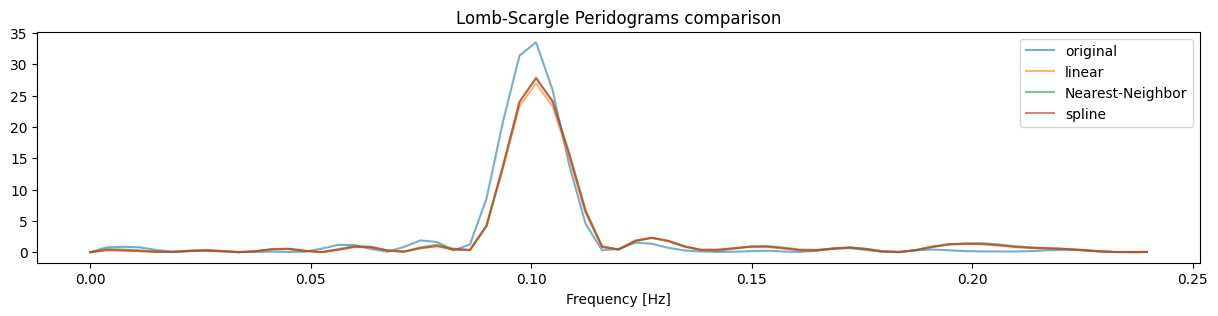

In [495]:
peridogram_original_ls = calc_periodogram_ls(x_nes)
peridogram_lin_ls = calc_periodogram_ls(x_lin)
peridogram_nn_ls = calc_periodogram_ls(x_nn)
peridogram_spline_ls = calc_periodogram_ls(x_spline)

plt.figure(figsize=(15, 3))
plt.title("Lomb-Scargle Peridograms comparison")
plt.plot(f_vec, peridogram_original_ls, label="original", alpha=0.6)
plt.plot(f_vec, peridogram_lin_ls, label="linear", alpha=0.6)
plt.plot(f_vec, peridogram_nn_ls, label="Nearest-Neighbor", alpha=0.6)
plt.plot(f_vec, peridogram_spline_ls, label="spline", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

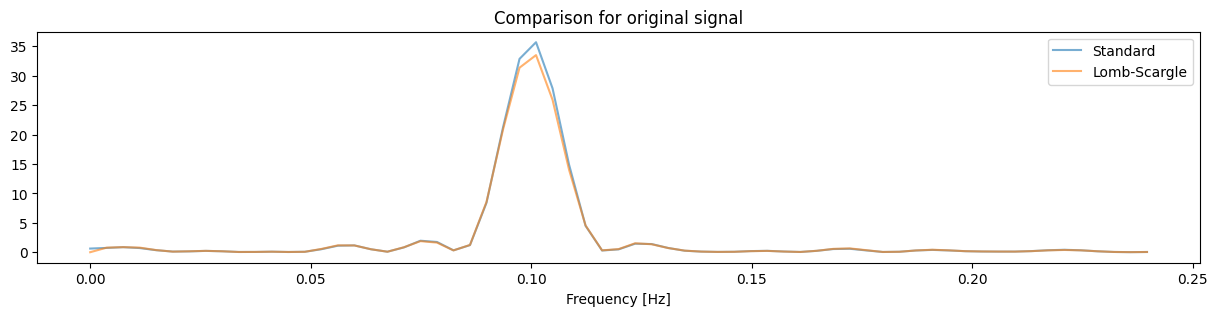

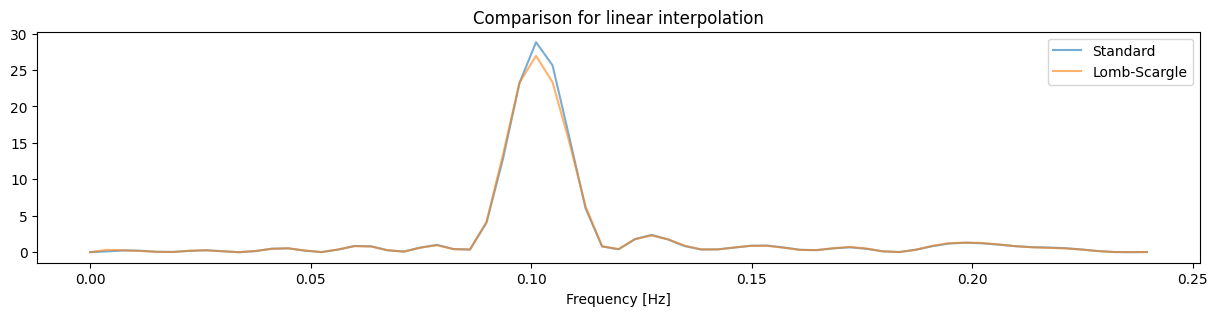

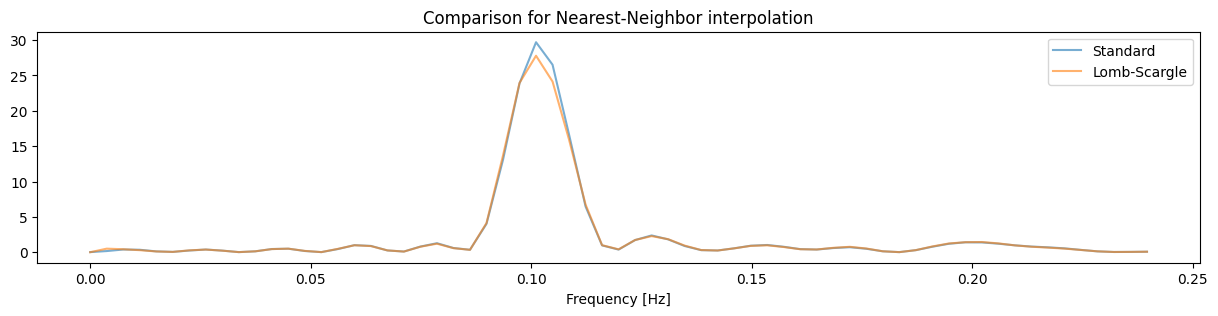

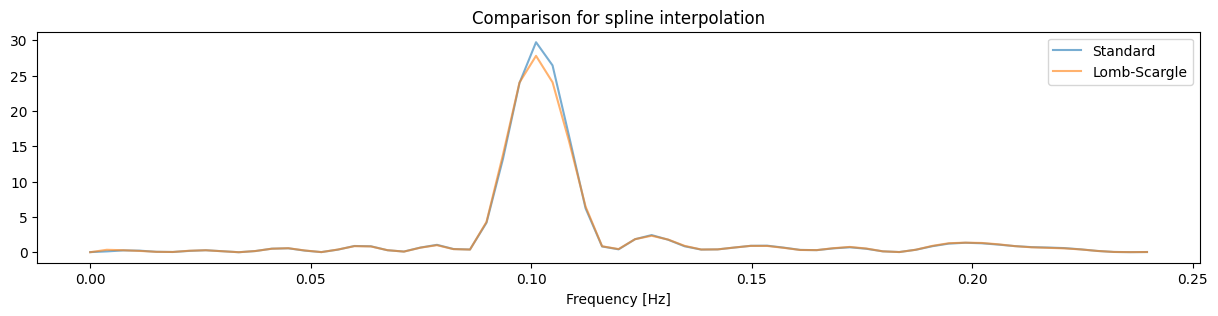

In [496]:
plt.figure(figsize=(15, 3))
plt.title("Comparison for original signal")
plt.plot(f_vec, peridogram_original, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_original_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

plt.figure(figsize=(15, 3))
plt.title("Comparison for linear interpolation")
plt.plot(f_vec, peridogram_lin, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_lin_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

plt.figure(figsize=(15, 3))
plt.title("Comparison for Nearest-Neighbor interpolation")
plt.plot(f_vec, peridogram_nn, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_nn_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

plt.figure(figsize=(15, 3))
plt.title("Comparison for spline interpolation")
plt.plot(f_vec, peridogram_spline, label="Standard", alpha=0.6)
plt.plot(f_vec, peridogram_spline_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()